# Industrial Fire & Accident Risk Predictor

The dataset has 100000 rows x 20 columns

## Column Descriptions (Total 20 Columns)

1. **Date:** Date of the sensor reading (YYYY-MM-DD).
2. **Time:** Timestamp of the reading (HH:MM:SS).
3. **Factory:** Name of the facility (Factory_A, B, C, D).
4. **Region:** Location of the factory (Urban, Rural, Industrial Zone).
5. **Shift:** Work shift timing (Day/Night).
6. **Workers:** Number of workers present (Contains 2% missing values).
7. **Exp:** Experience level of the workforce (Junior/Senior).
8. **Training:** Whether workers have received Safety Training (Yes/No).
9. **Temp:** Ambient temperature in C (Key indicator for fire risk).
10. **Pressure:** Machine pressure in Psi (Contains 0.5% outliers).
11. **Humidity:** Environmental humidity percentage.
12. **Vibration:** Machine vibration levels.
13. **Speed:** Machine operational speed (RPM).
14. **Age:** Age of the machine in years.
15. **Service_Days:** Days since the last Machine Service.
16. **Gas:** Gas leakage levels detected by sensors.
17. **Sparks:** Count of sparks detected during operation.
18. **Alarm:** Status of the emergency Alarm System (On/Off).
19. **Risk:** (Target 1) Calculated Fire Risk Score (0-100).
20. **Accident:** (Target 2) Binary label indicating if an accident occurred (0 = Safe, 1 = Accident).

## 1. Load Dataset and Import Libraries

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Evaluation & Threshold Optimization
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    precision_score,accuracy_score,
    recall_score,
    f1_score)

# Display settings
pd.set_option('display.max_colwidth', None)


In [2]:
df=pd.read_csv("industrial_fire_risk_data.csv")
df.head()

,Date,Time,Factory,Region,Shift,Workers,Exp,Training,Temp,Pressure,Humidity,Vibration,Speed,Age,Service_Days,Gas,Sparks,Alarm,Risk,Accident
0,2021-01-01,00:00:00,Factory_A,Urban,Day,7.0,Junior,Yes,26.49,25.31,54.18,1.63,1007.06,17,202,8.90,1,Off,56.47,0
1,2021-01-01,00:15:00,Factory_A,Industrial_Zone,Night,11.0,Junior,Yes,24.59,19.98,68.53,3.10,2664.56,7,217,9.97,3,Off,48.28,0
2,2021-01-01,00:30:00,Factory_C,Urban,Day,14.0,Junior,No,26.94,24.62,79.44,4.31,2335.27,6,32,8.66,4,On,32.13,0
3,2021-01-01,00:45:00,Factory_B,Rural,Night,20.0,Senior,No,29.57,23.55,77.35,1.48,3806.65,10,276,2.71,1,Off,59.04,0
4,2021-01-01,01:00:00,Factory_B,Urban,Day,38.0,Junior,No,24.30,21.49,47.83,0.51,1147.47,16,303,5.87,4,On,53.32,0


## 2. Exploratory Data Analysis

This section provides an initial understanding of the dataset by examining its structure, feature distributions, and key characteristics.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Date          100000 non-null  object 
 1   Time          100000 non-null  object 
 2   Factory       100000 non-null  object 
 3   Region        100000 non-null  object 
 4   Shift         100000 non-null  object 
 5   Workers       98000 non-null   float64
 6   Exp           100000 non-null  object 
 7   Training      100000 non-null  object 
 8   Temp          100000 non-null  float64
 9   Pressure      100000 non-null  float64
 10  Humidity      100000 non-null  float64
 11  Vibration     100000 non-null  float64
 12  Speed         100000 non-null  float64
 13  Age           100000 non-null  int64  
 14  Service_Days  100000 non-null  int64  
 15  Gas           100000 non-null  float64
 16  Sparks        100000 non-null  int64  
 17  Alarm         100000 non-null  object 
 18  Risk 

### 2.1 Column Details, Unique Values and Missing Values

In [4]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(f"Data Type: {df[col].dtype}")
    print(f"Unique Values: {df[col].nunique()}")
    print(f"Missing Values: {df[col].isnull().sum()}")
    print(f"Sample Values: {df[col].unique()[:10]}")
    print("-" * 50)


Column: Date
Data Type: object
Unique Values: 1042
Missing Values: 0
Sample Values: ['2021-01-01' '2021-01-02' '2021-01-03' '2021-01-04' '2021-01-05'
 '2021-01-06' '2021-01-07' '2021-01-08' '2021-01-09' '2021-01-10']
--------------------------------------------------

Column: Time
Data Type: object
Unique Values: 96
Missing Values: 0
Sample Values: ['00:00:00' '00:15:00' '00:30:00' '00:45:00' '01:00:00' '01:15:00'
 '01:30:00' '01:45:00' '02:00:00' '02:15:00']
--------------------------------------------------

Column: Factory
Data Type: object
Unique Values: 4
Missing Values: 0
Sample Values: ['Factory_A' 'Factory_C' 'Factory_B' 'Factory_D']
--------------------------------------------------

Column: Region
Data Type: object
Unique Values: 3
Missing Values: 0
Sample Values: ['Urban' 'Industrial_Zone' 'Rural']
--------------------------------------------------

Column: Shift
Data Type: object
Unique Values: 2
Missing Values: 0
Sample Values: ['Day' 'Night']
----------------------------

In [5]:
print("Missing Values:")
display(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:


Date               0
Time               0
Factory            0
Region             0
Shift              0
Workers         2000
Exp                0
Training           0
Temp               0
Pressure           0
Humidity           0
Vibration          0
Speed              0
Age                0
Service_Days       0
Gas                0
Sparks             0
Alarm              0
Risk               0
Accident           0
dtype: int64

Duplicate Rows: 0


### 2.2 Outlier Detection

In [6]:
for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | 
                  (df[col] > Q3 + 1.5 * IQR)]
    
    print(col, ":", len(outliers))

Workers : 0
Temp : 0
Pressure : 508
Humidity : 0
Vibration : 0
Speed : 0
Age : 0
Service_Days : 0
Gas : 0
Sparks : 0
Risk : 24
Accident : 4093


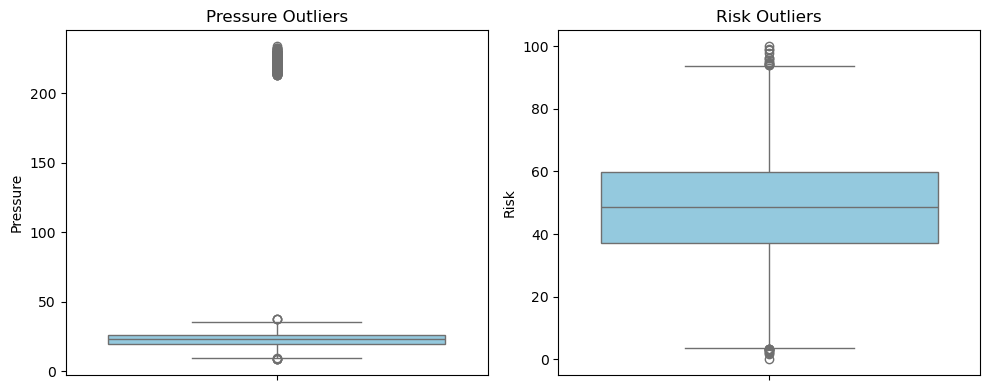

In [ ]:
cols = ['Pressure', 'Risk']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(f'{col} Outliers')

plt.tight_layout()
plt.show()

### 2.3 Target Variable Analysis


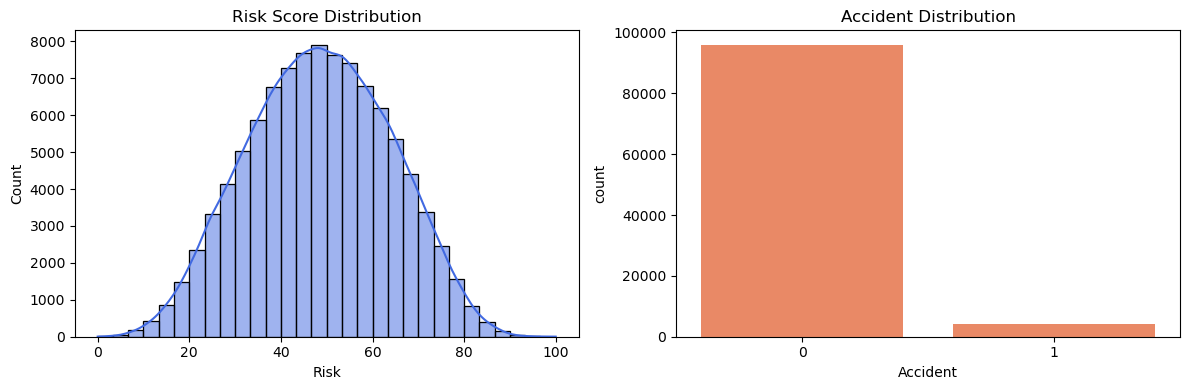

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Risk'], bins=30, kde=True,
             color='royalblue', ax=axes[0])
axes[0].set_title('Risk Score Distribution')
sns.countplot(x='Accident', data=df,
              color='coral', ax=axes[1])
axes[1].set_title('Accident Distribution')

plt.tight_layout()
plt.show()

### 2.5 Correlation Analysis

This section examines the correlations between numerical features to identify relationships and potential patterns in the dataset.

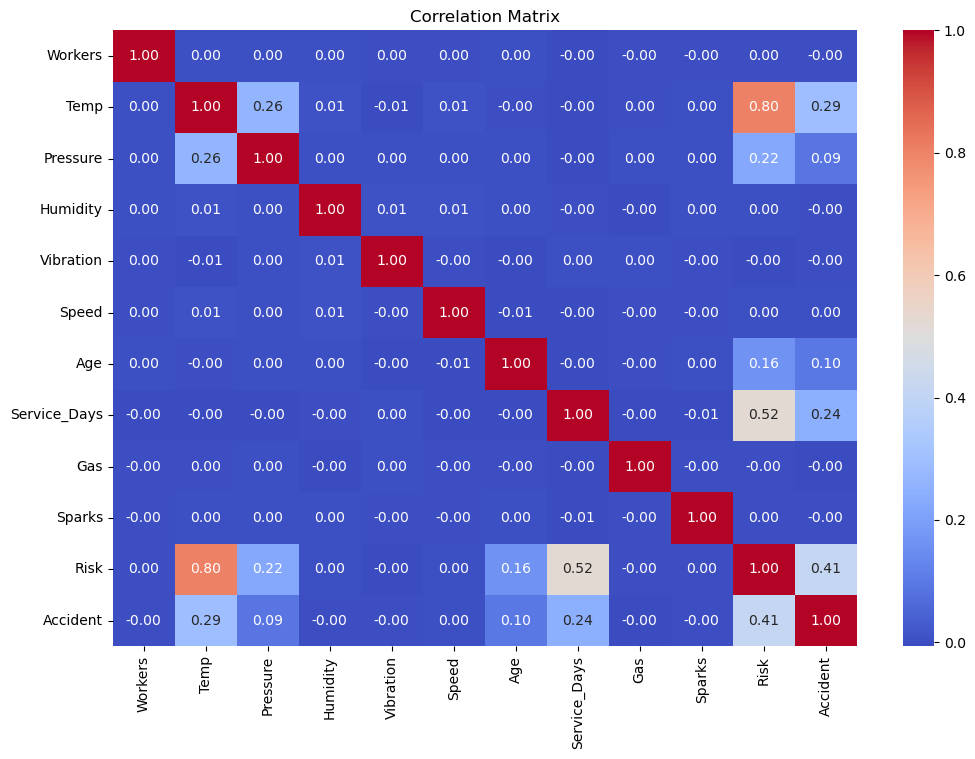

In [13]:
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## 3. Data Preprocessing

This section focuses on cleaning the dataset, handling missing values, and preparing the data for feature engineering and model development.

In [15]:
# Extract the month and create the 'Season' column
df['Date'] = pd.to_datetime(df['Date'])
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['Season'] = df['Date'].dt.month.map(get_season)

In [16]:
low = df['Gas'].quantile(0.33)
high = df['Gas'].quantile(0.66)
def categorize_gas(gas):
    if gas <= low:
        return 'Low'
    elif gas <= high:
        return 'Medium'
    else:
        return 'High'
df['Gas_Level'] = df['Gas'].apply(categorize_gas)

In [17]:
###  Machine Age Group Creation
df['Machine_Age_Group'] = pd.cut(
    df['Age'],
    bins=[-1, 5, 10, float('inf')],
    labels=['New', 'Medium', 'Old']
)

In [18]:
### Temperature-Gas Interaction Feature
df['Temp_Gas_Interaction'] = df['Temp'] * df['Gas']

In [19]:
df

,Date,Time,Factory,Region,Shift,Workers,Exp,Training,Temp,Pressure,...,Service_Days,Gas,Sparks,Alarm,Risk,Accident,Season,Gas_Level,Machine_Age_Group,Temp_Gas_Interaction
0,2021-01-01,00:00:00,Factory_A,Urban,Day,7.0,Junior,Yes,26.49,25.31,...,202,8.90,1,Off,56.47,0,Winter,High,Old,235.7610
1,2021-01-01,00:15:00,Factory_A,Industrial_Zone,Night,11.0,Junior,Yes,24.59,19.98,...,217,9.97,3,Off,48.28,0,Winter,High,Medium,245.1623
2,2021-01-01,00:30:00,Factory_C,Urban,Day,14.0,Junior,No,26.94,24.62,...,32,8.66,4,On,32.13,0,Winter,High,Medium,233.3004
3,2021-01-01,00:45:00,Factory_B,Rural,Night,20.0,Senior,No,29.57,23.55,...,276,2.71,1,Off,59.04,0,Winter,Low,Medium,80.1347
4,2021-01-01,01:00:00,Factory_B,Urban,Day,38.0,Junior,No,24.30,21.49,...,303,5.87,4,On,53.32,0,Winter,Medium,Old,142.6410
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2023-11-08,14:45:00,Factory_A,Urban,Day,9.0,Junior,No,15.66,15.30,...,144,9.03,1,On,36.24,0,Autumn,High,Old,141.4098
99996,2023-11-08,15:00:00,Factory_C,Industrial_Zone,Day,7.0,Junior,Yes,14.63,18.45,...,191,4.08,0,On,24.55,0,Autumn,Medium,New,59.6904
99997,2023-11-08,15:15:00,Factory_B,Rural,Night,14.0,Junior,Yes,17.57,19.10,...,153,2.61,0,On,33.74,0,Autumn,Low,Old,45.8577
99998,2023-11-08,15:30:00,Factory_C,Rural,Day,12.0,Junior,Yes,15.71,19.56,...,297,2.76,1,Off,45.28,0,Autumn,Low,Old,43.3596


In [49]:
df[df["Accident"] == 0]

,Date,Time,Factory,Region,Shift,Workers,Exp,Training,Temp,Pressure,Humidity,Vibration,Speed,Age,Service_Days,Gas,Sparks,Alarm,Risk,Accident
0,2021-01-01,00:00:00,Factory_A,Urban,Day,7.0,Junior,Yes,26.49,25.31,54.18,1.63,1007.06,17,202,8.90,1,Off,56.47,0
1,2021-01-01,00:15:00,Factory_A,Industrial_Zone,Night,11.0,Junior,Yes,24.59,19.98,68.53,3.10,2664.56,7,217,9.97,3,Off,48.28,0
2,2021-01-01,00:30:00,Factory_C,Urban,Day,14.0,Junior,No,26.94,24.62,79.44,4.31,2335.27,6,32,8.66,4,On,32.13,0
3,2021-01-01,00:45:00,Factory_B,Rural,Night,20.0,Senior,No,29.57,23.55,77.35,1.48,3806.65,10,276,2.71,1,Off,59.04,0
4,2021-01-01,01:00:00,Factory_B,Urban,Day,38.0,Junior,No,24.30,21.49,47.83,0.51,1147.47,16,303,5.87,4,On,53.32,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2023-11-08,14:45:00,Factory_A,Urban,Day,9.0,Junior,No,15.66,15.30,51.19,1.12,1568.11,16,144,9.03,1,On,36.24,0
99996,2023-11-08,15:00:00,Factory_C,Industrial_Zone,Day,7.0,Junior,Yes,14.63,18.45,59.42,2.75,3111.77,4,191,4.08,0,On,24.55,0
99997,2023-11-08,15:15:00,Factory_B,Rural,Night,14.0,Junior,Yes,17.57,19.10,50.53,4.31,2613.91,13,153,2.61,0,On,33.74,0
99998,2023-11-08,15:30:00,Factory_C,Rural,Day,12.0,Junior,Yes,15.71,19.56,69.72,3.00,2210.63,16,297,2.76,1,Off,45.28,0


### 5. Column Drop Analysis
1. **Date** — removed because relevant seasonal information is extracted into the `Season` feature.
2. **Time** — removed because the raw timestamp is not directly used; relevant time-based features can be extracted separately.
3. **Risk** — removed from the input features to focus on predicting `Accident` without using the other target variable as a predictor.

In [20]:
drop_cols = [
    "Time",'Date',
      "Risk"
]
X = df.drop(columns=drop_cols + ["Accident"])
y = df["Accident"]

## 6. Train-Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80000, 20)
X_test shape: (20000, 20)
y_train shape: (80000,)
y_test shape: (20000,)


## 7. Identify Numerical and Categorical Features

This step separates numerical and categorical features to apply appropriate preprocessing techniques within the machine learning pipeline.

In [22]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['Workers', 'Temp', 'Pressure', 'Humidity', 'Vibration', 'Speed', 'Age', 'Service_Days', 'Gas', 'Sparks', 'Temp_Gas_Interaction']
Categorical: ['Factory', 'Region', 'Shift', 'Exp', 'Training', 'Alarm', 'Season', 'Gas_Level']


## 8. Data Preprocessing Pipeline

In [23]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [24]:
ordinal_cols = ['Machine_Age_Group', 'Gas_Level']
onehot_cols = [col for col in cat_cols if col not in ordinal_cols]
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ['New', 'Medium', 'Old'],
            ['Low', 'Medium', 'High']
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

onehot_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

### 8.3 Combined Preprocessing Pipeline

This step combines numerical and categorical preprocessing pipelines into a single ColumnTransformer. Numerical features are imputed and scaled, ordinal features are encoded according to their natural order, and the remaining categorical features are transformed using one-hot encoding.

In [25]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("onehot", onehot_pipeline, onehot_cols)
])

### 9.1 Logistic Regression Model

This step builds a Logistic Regression model by combining the preprocessing pipeline with the classifier. The `class_weight="balanced"` parameter helps address class imbalance by assigning greater weight to the minority class

In [26]:
lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [27]:
lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Workers', 'Temp', 'Pressure', 'Humidity', 'Vibration', 'Speed', 'Age',
       'Service_Days', 'Gas', 'Sparks', 'Temp_Gas_Interaction'],
      dtype='object')),
                                                 ('ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleI...
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['Machine_Age_Group',
                                                   'Gas_Level']),
                                                 ('onehot',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Factory', 'Region', 'Shift',
                                                   'Exp', 'Training', 'Alarm',
                                                   'Season'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [28]:
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

In [30]:
from sklearn.metrics import roc_auc_score

In [31]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))


Accuracy : 0.9451
Precision: 0.42479784366576817
Recall   : 0.9621489621489622
F1 Score : 0.5893792071802543
ROC-AUC  : 0.9893735781854233


In [32]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97     19181
           1       0.42      0.96      0.59       819

    accuracy                           0.95     20000
   macro avg       0.71      0.95      0.78     20000
weighted avg       0.97      0.95      0.95     20000



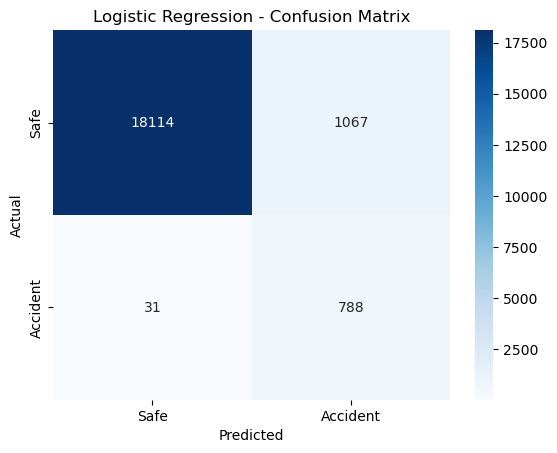

In [33]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Accident"],
    yticklabels=["Safe", "Accident"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


### 9.1.1 Logistic Regression Feature Importance

In [34]:
feature_names = lr.named_steps["preprocessor"].get_feature_names_out()
coefficients = lr.named_steps["model"].coef_[0]
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": abs(coefficients)
})

importance = importance.sort_values(
    "importance",
    ascending=False
)
print(importance.head(20))

                           feature  importance
1                        num__Temp    7.318012
7                num__Service_Days    4.756563
22              onehot__Exp_Junior    1.651353
27                onehot__Alarm_On    1.617232
25            onehot__Training_Yes    1.575795
21             onehot__Shift_Night    1.561761
20               onehot__Shift_Day    1.551949
6                         num__Age    1.546618
24             onehot__Training_No    1.537916
26               onehot__Alarm_Off    1.496478
23              onehot__Exp_Senior    1.462357
18            onehot__Region_Rural    1.116274
17  onehot__Region_Industrial_Zone    1.028786
19            onehot__Region_Urban    0.968650
13       onehot__Factory_Factory_A    0.833362
31           onehot__Season_Winter    0.827732
29           onehot__Season_Spring    0.798202
14       onehot__Factory_Factory_B    0.785977
28           onehot__Season_Autumn    0.765012
16       onehot__Factory_Factory_D    0.759791


In [35]:
df[(df["Temp"] > 38) & (df["Accident"] == 1)]

,Date,Time,Factory,Region,Shift,Workers,Exp,Training,Temp,Pressure,...,Service_Days,Gas,Sparks,Alarm,Risk,Accident,Season,Gas_Level,Machine_Age_Group,Temp_Gas_Interaction
3241,2021-02-03,18:15:00,Factory_C,Urban,Night,37.0,Senior,No,38.61,29.12,...,201,6.18,4,On,76.85,1,Winter,Medium,Old,238.6098
3716,2021-02-08,17:00:00,Factory_A,Rural,Night,10.0,Junior,No,39.73,26.38,...,330,9.19,3,On,77.61,1,Winter,High,New,365.1187
4870,2021-02-20,17:30:00,Factory_C,Rural,Day,6.0,Senior,Yes,39.23,30.08,...,357,0.85,4,On,88.01,1,Winter,Low,Old,33.3455
5709,2021-03-01,11:15:00,Factory_D,Industrial_Zone,Night,13.0,Senior,No,39.36,30.31,...,323,6.95,4,On,94.69,1,Spring,High,Old,273.5520
5721,2021-03-01,14:15:00,Factory_A,Industrial_Zone,Day,13.0,Junior,No,38.83,28.07,...,333,3.13,1,On,86.04,1,Spring,Low,Old,121.5379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85273,2023-06-08,06:15:00,Factory_C,Rural,Night,37.0,Junior,Yes,38.65,30.55,...,293,5.64,0,On,76.65,1,Summer,Medium,Old,217.9860
85870,2023-06-14,11:30:00,Factory_A,Rural,Day,39.0,Senior,No,38.36,25.97,...,336,6.67,4,On,78.80,1,Summer,High,Old,255.8612
86159,2023-06-17,11:45:00,Factory_B,Urban,Day,38.0,Senior,No,39.26,32.92,...,341,7.68,1,Off,86.13,1,Summer,High,New,301.5168
86704,2023-06-23,04:00:00,Factory_C,Industrial_Zone,Day,33.0,Senior,No,38.04,34.39,...,258,5.22,0,On,77.70,1,Summer,Medium,New,198.5688


In [36]:
df[(df["Temp"] > 38) & (df["Accident"] == 0)]

,Date,Time,Factory,Region,Shift,Workers,Exp,Training,Temp,Pressure,...,Service_Days,Gas,Sparks,Alarm,Risk,Accident,Season,Gas_Level,Machine_Age_Group,Temp_Gas_Interaction
3982,2021-02-11,11:30:00,Factory_A,Industrial_Zone,Night,26.0,Senior,Yes,39.46,29.62,...,131,7.00,0,Off,67.64,0,Winter,High,Old,276.2200
4047,2021-02-12,03:45:00,Factory_C,Industrial_Zone,Night,21.0,Senior,No,38.44,28.33,...,75,0.83,2,Off,59.40,0,Winter,Low,Medium,31.9052
4784,2021-02-19,20:00:00,Factory_D,Industrial_Zone,Night,42.0,Senior,No,38.27,26.67,...,327,0.90,1,Off,72.18,0,Winter,Low,New,34.4430
4997,2021-02-22,01:15:00,Factory_C,Urban,Day,31.0,Senior,Yes,39.34,31.25,...,8,6.56,1,On,56.58,0,Winter,Medium,New,258.0704
5157,2021-02-23,17:15:00,Factory_A,Rural,Day,49.0,Senior,Yes,38.75,28.35,...,137,3.63,2,Off,69.98,0,Winter,Medium,Old,140.6625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85164,2023-06-07,03:00:00,Factory_C,Industrial_Zone,Day,28.0,Senior,Yes,39.92,28.94,...,22,3.20,1,On,54.51,0,Summer,Low,New,127.7440
86247,2023-06-18,09:45:00,Factory_A,Industrial_Zone,Night,37.0,Senior,No,38.62,26.52,...,90,9.30,4,On,62.24,0,Summer,High,Old,359.1660
86664,2023-06-22,18:00:00,Factory_C,Rural,Day,39.0,Junior,No,38.05,30.42,...,145,0.85,4,Off,60.74,0,Summer,Low,New,32.3425
86729,2023-06-23,10:15:00,Factory_C,Urban,Night,49.0,Senior,No,38.37,27.94,...,57,5.38,1,On,58.27,0,Summer,Medium,New,206.4306


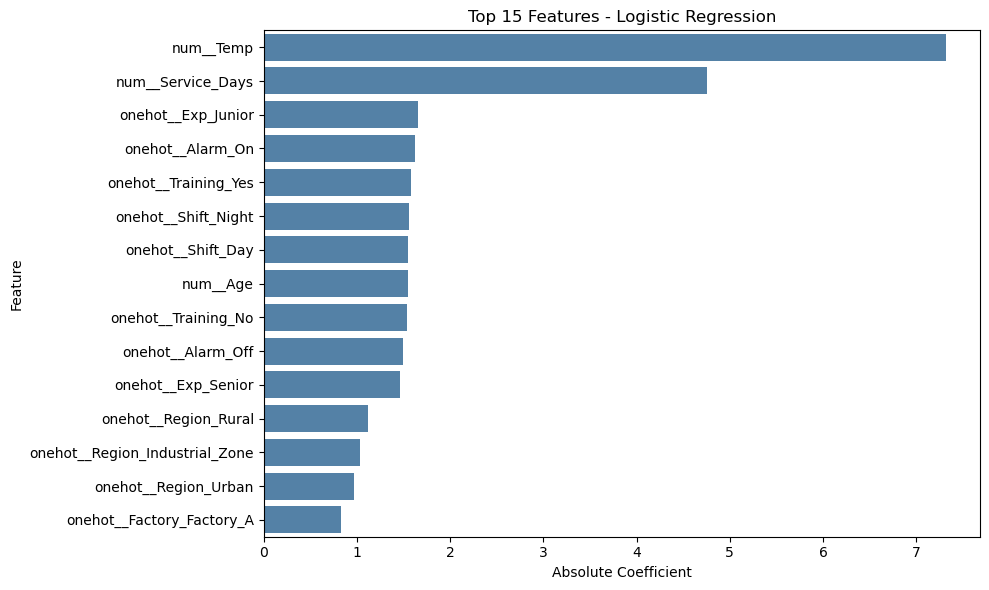

In [37]:
top_features = importance.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="importance",
    y="feature",
    color="steelblue"
)

plt.title("Top 15 Features - Logistic Regression")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 9.2 Random Forest Classifier

In [38]:
rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

In [39]:
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [40]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf))


Accuracy : 0.97605
Precision: 0.8256704980842912
Recall   : 0.5262515262515263
F1 Score : 0.6428038777032066
ROC-AUC  : 0.988071096251066


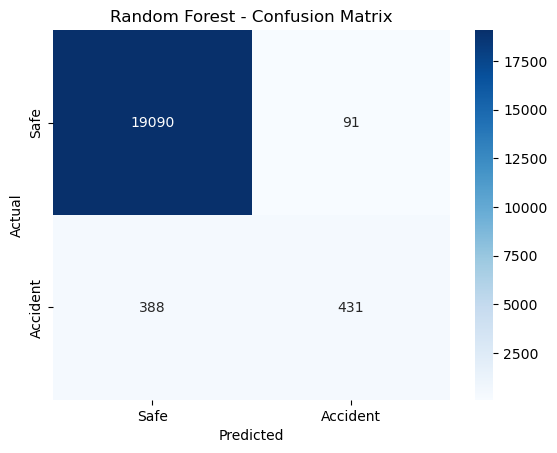

In [41]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Accident"],
    yticklabels=["Safe", "Accident"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()


In [46]:
importance_rf = pd.DataFrame({
    "Feature": rf.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": rf.named_steps["model"].feature_importances_
})

importance_rf = importance_rf.sort_values(
    "Importance", ascending=False
)

print(importance_rf.head(20))

                           Feature  Importance
1                        num__Temp    0.263136
7                num__Service_Days    0.247300
2                    num__Pressure    0.167619
29           onehot__Season_Spring    0.105877
6                         num__Age    0.027044
28           onehot__Season_Autumn    0.026722
10       num__Temp_Gas_Interaction    0.024716
8                         num__Gas    0.015655
3                    num__Humidity    0.014291
5                       num__Speed    0.014090
4                   num__Vibration    0.013591
11      ordinal__Machine_Age_Group    0.013082
30           onehot__Season_Summer    0.012386
0                     num__Workers    0.011303
31           onehot__Season_Winter    0.010819
9                      num__Sparks    0.004977
12              ordinal__Gas_Level    0.003810
19            onehot__Region_Urban    0.001729
18            onehot__Region_Rural    0.001690
17  onehot__Region_Industrial_Zone    0.001646


In [42]:
cm_rf

array([[19090,    91],
       [  388,   431]])

### 9.3 Decision tree Classifier

In [47]:
dt = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced",
        max_depth=5
    ))
])

In [48]:
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]


In [49]:
print("Decision Tree Results")
print("=====================")
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall   :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Decision Tree Results
Accuracy : 0.9262
Precision: 0.3531515422440769
Recall   : 0.9645909645909646
F1 Score : 0.5170157068062827
ROC-AUC  : 0.9707437451298564

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     19181
           1       0.35      0.96      0.52       819

    accuracy                           0.93     20000
   macro avg       0.68      0.94      0.74     20000
weighted avg       0.97      0.93      0.94     20000



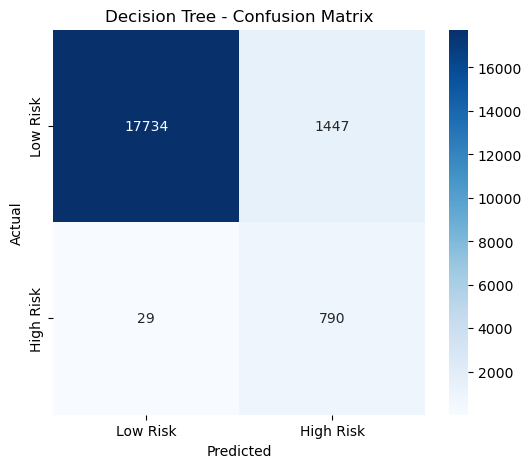

In [50]:
dt_cm = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [51]:
importance_dt = pd.DataFrame({
    "Feature": dt.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": dt.named_steps["model"].feature_importances_
})

importance_dt = importance_dt.sort_values(
    "Importance", ascending=False
)

print(importance_dt.head(20))

                           Feature    Importance
1                        num__Temp  7.071477e-01
7                num__Service_Days  2.683507e-01
6                         num__Age  2.010789e-02
2                    num__Pressure  3.970485e-03
3                    num__Humidity  3.036057e-04
10       num__Temp_Gas_Interaction  1.196120e-04
19            onehot__Region_Urban  1.266433e-15
5                       num__Speed  0.000000e+00
4                   num__Vibration  0.000000e+00
8                         num__Gas  0.000000e+00
9                      num__Sparks  0.000000e+00
11      ordinal__Machine_Age_Group  0.000000e+00
12              ordinal__Gas_Level  0.000000e+00
13       onehot__Factory_Factory_A  0.000000e+00
14       onehot__Factory_Factory_B  0.000000e+00
0                     num__Workers  0.000000e+00
15       onehot__Factory_Factory_C  0.000000e+00
16       onehot__Factory_Factory_D  0.000000e+00
17  onehot__Region_Industrial_Zone  0.000000e+00
18            onehot

### 10. Model Evaluation and Comparison

In [52]:
models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf
}

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name} Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Logistic Regression Confusion Matrix:
[[18114  1067]
 [   31   788]]

Decision Tree Confusion Matrix:
[[17734  1447]
 [   29   790]]

Random Forest Confusion Matrix:
[[19090    91]
 [  388   431]]


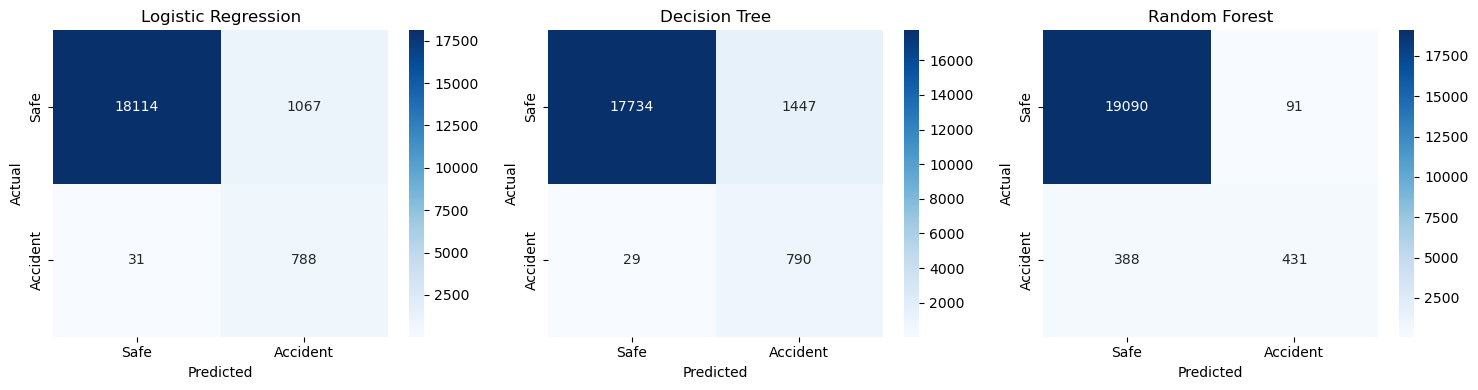

In [53]:
models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Safe", "Accident"],
        yticklabels=["Safe", "Accident"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.945,0.425,0.962,0.589,0.989
1,Decision Tree,0.926,0.353,0.965,0.517,0.971
2,Random Forest,0.976,0.826,0.526,0.643,0.988


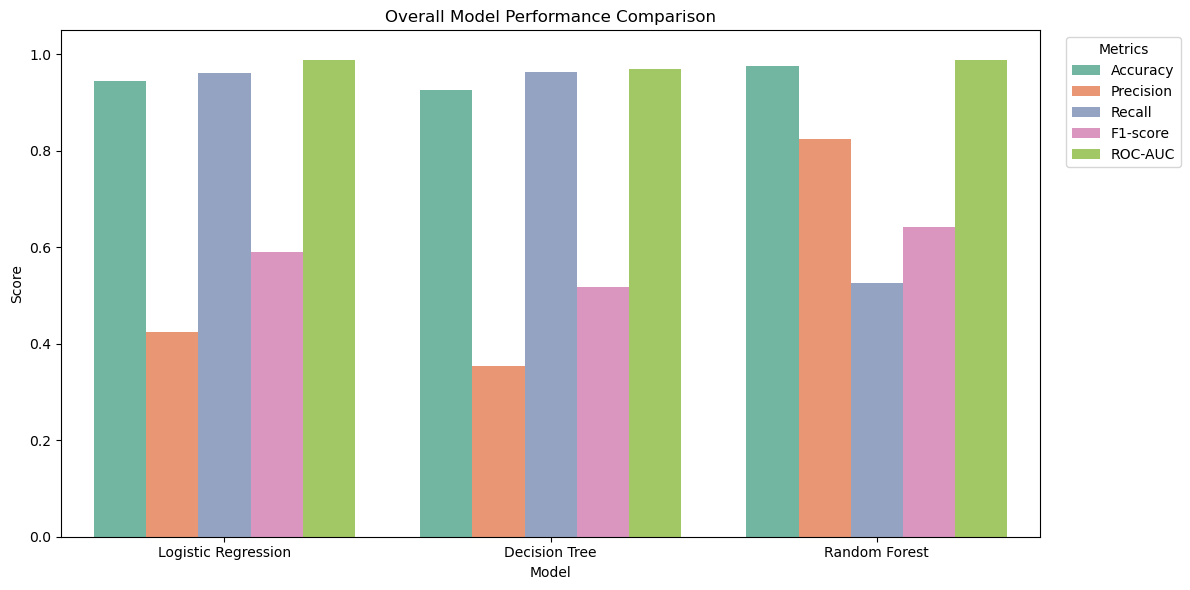

In [54]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

metrics_df = pd.DataFrame(results)
display(metrics_df.round(3))

plot_df = metrics_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Overall Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 11. Threshold Optimization
This section optimizes the classification threshold for Logistic Regression, Decision Tree, and Random Forest. The goal is to achieve high Recall while maintaining acceptable Precision. Thresholds are selected using validation data to reduce missed accidents and unnecessary false alarms.

11.2 Optimized Threshold Comparison

This comparison evaluates the models using a target Recall of approximately 98%. Logistic Regression achieved 98.2% Recall and missed 12 accidents, while Random Forest achieved 98.0% Recall and missed 13 accidents. Both models performed similarly, whereas Decision Tree generated substantially more false alarms. Logistic Regression is selected as a candidate model due to its high accident detection rate and competitive overall performance.


Logistic Regression
Threshold: 0.2632
Confusion Matrix:
 [[17638  1543]
 [    8   811]]
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     19181
           1       0.34      0.99      0.51       819

    accuracy                           0.92     20000
   macro avg       0.67      0.95      0.73     20000
weighted avg       0.97      0.92      0.94     20000


Decision Tree
Threshold: 0.0052
Confusion Matrix:
 [[14595  4586]
 [    8   811]]
              precision    recall  f1-score   support

           0       1.00      0.76      0.86     19181
           1       0.15      0.99      0.26       819

    accuracy                           0.77     20000
   macro avg       0.57      0.88      0.56     20000
weighted avg       0.96      0.77      0.84     20000


Random Forest
Threshold: 0.04
Confusion Matrix:
 [[17607  1574]
 [    7   812]]
              precision    recall  f1-score   support

           0       1.00      0.92     

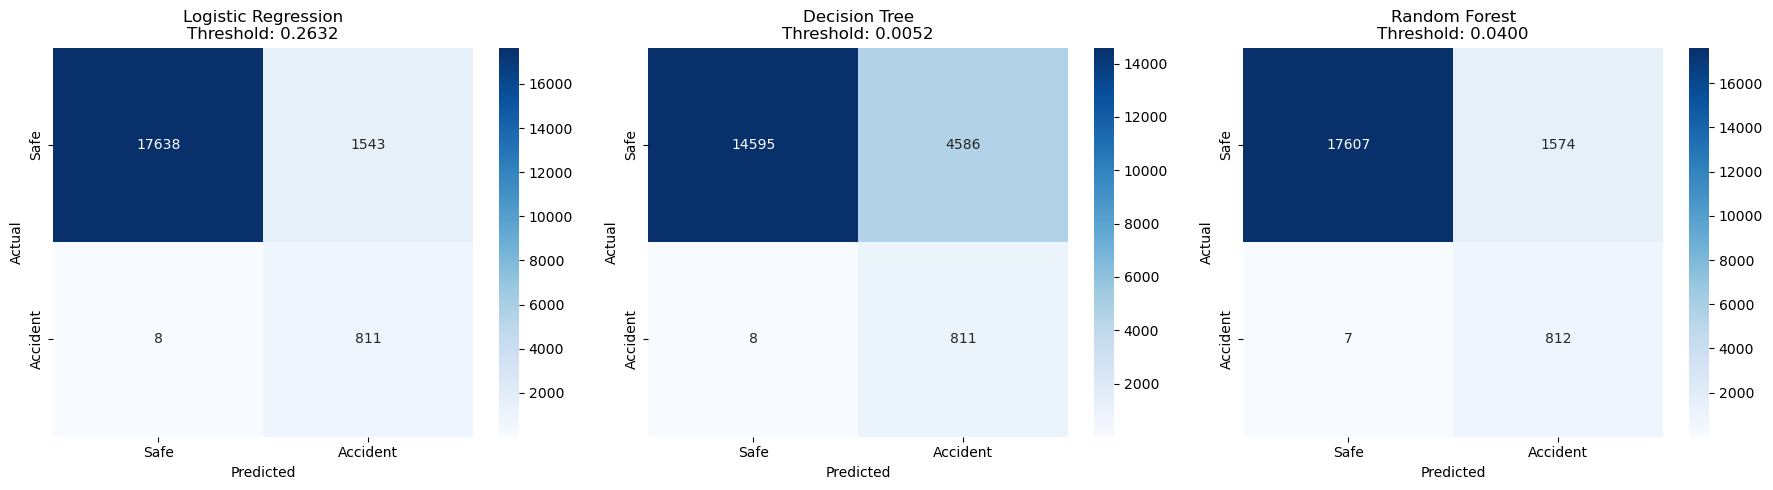

In [ ]:
target_recall = 0.99

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf
}

results = {}
summary = []

for name, model in models.items():

    y_probs = model.predict_proba(X_test)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(
        y_test, y_probs)

    
    valid_indices = np.where(recalls[:-1] >= target_recall)[0]

    if len(valid_indices) == 0:
        print(f"{name}: 99% Recall təmin edən threshold tapılmadı.")
        continue

    # Recall >= 99% olanlar arasında ən yüksək Precision
    best_index = valid_indices[
        np.argmax(precisions[:-1][valid_indices])
    ]

    best_threshold = thresholds[best_index]

    # Seçilmiş threshold ilə proqnoz
    y_pred = (y_probs >= best_threshold).astype(int)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    results[name] = {
        "threshold": best_threshold,
        "y_pred": y_pred,
        "cm": cm
    }

    summary.append({
        "Model": name,
        "Threshold": round(best_threshold, 4),
        "Precision": round(tp / (tp + fp), 4) if tp + fp else 0,
        "Recall": round(tp / (tp + fn), 4) if tp + fn else 0,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

    print("\n" + "=" * 50)
    print(name)
    print("Threshold:", round(best_threshold, 4))
    print("Confusion Matrix:\n", cm)
    print(classification_report(y_test, y_pred, zero_division=0))

# Müqayisə cədvəli
summary_df = pd.DataFrame(summary)

print("\nMODELLƏRİN MÜQAYİSƏSİ")
print(summary_df.to_string(index=False))

# Confusion Matrix qrafikləri
if results:
    fig, axes = plt.subplots(
        1, len(results), figsize=(6 * len(results), 5)
    )

    axes = np.atleast_1d(axes)

    for ax, (name, result) in zip(axes, results.items()):
        sns.heatmap(
            result["cm"],
            annot=True,
            fmt="d",
            cmap="Blues",
            ax=ax,
            xticklabels=["Safe", "Accident"],
            yticklabels=["Safe", "Accident"]
        )

        ax.set_title(
            f'{name}\nThreshold: {result["threshold"]:.4f}'
        )
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.tight_layout()
    plt.show()

In [63]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (60000, 20)
Validation: (20000, 20)
Test: (20000, 20)


In [64]:
lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Workers', 'Temp', 'Pressure', 'Humidity', 'Vibration', 'Speed', 'Age',
       'Service_Days', 'Gas', 'Sparks', 'Temp_Gas_Interaction'],
      dtype='object')),
                                                 ('ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleI...
                                                                                  unknown_value=-1))]),
                                                  ['Machine_Age_Group',
                                                   'Gas_Level']),
                                                 ('onehot',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Factory', 'Region', 'Shift',
                                                   'Exp', 'Training', 'Alarm',
                                                   'Season'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [78]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    recall_score,
    precision_score
)

target_recall = 0.98

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf
}

thresholds = {}
results = []

for name, model in models.items():

    # Select the threshold using validation data
    probs_val = model.predict_proba(X_val)[:, 1]

    precision, recall, thrs = precision_recall_curve(
        y_val, probs_val
    )

    # Find thresholds that satisfy 98% Recall
    valid = np.where(recall[:-1] >= target_recall)[0]

    if len(valid) == 0:
        print(f"{name}: No threshold satisfies 98% Recall.")
        continue

    # Select the threshold with the highest Precision
    best = valid[np.argmax(precision[valid])]
    threshold = thrs[best]

    thresholds[name] = threshold

    # Evaluate predictions on validation data
    pred_val = (probs_val >= threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": round(threshold, 4),
        "Val Recall": round(
            recall_score(y_val, pred_val), 4
        ),
        "Val Precision": round(
            precision_score(
                y_val, pred_val, zero_division=0
            ), 4
        )
    })

# Display model comparison
summary_df = pd.DataFrame(results)

print("\n" + " VALIDATION RESULTS ".center(60, "="))
print(summary_df.to_string(index=False))



==================== VALIDATION RESULTS ====================
              Model  Threshold  Val Recall  Val Precision
Logistic Regression     0.4522      0.9804         0.4223
      Decision Tree     0.2371      0.9841         0.3069
      Random Forest     0.0650      0.9804         0.4048


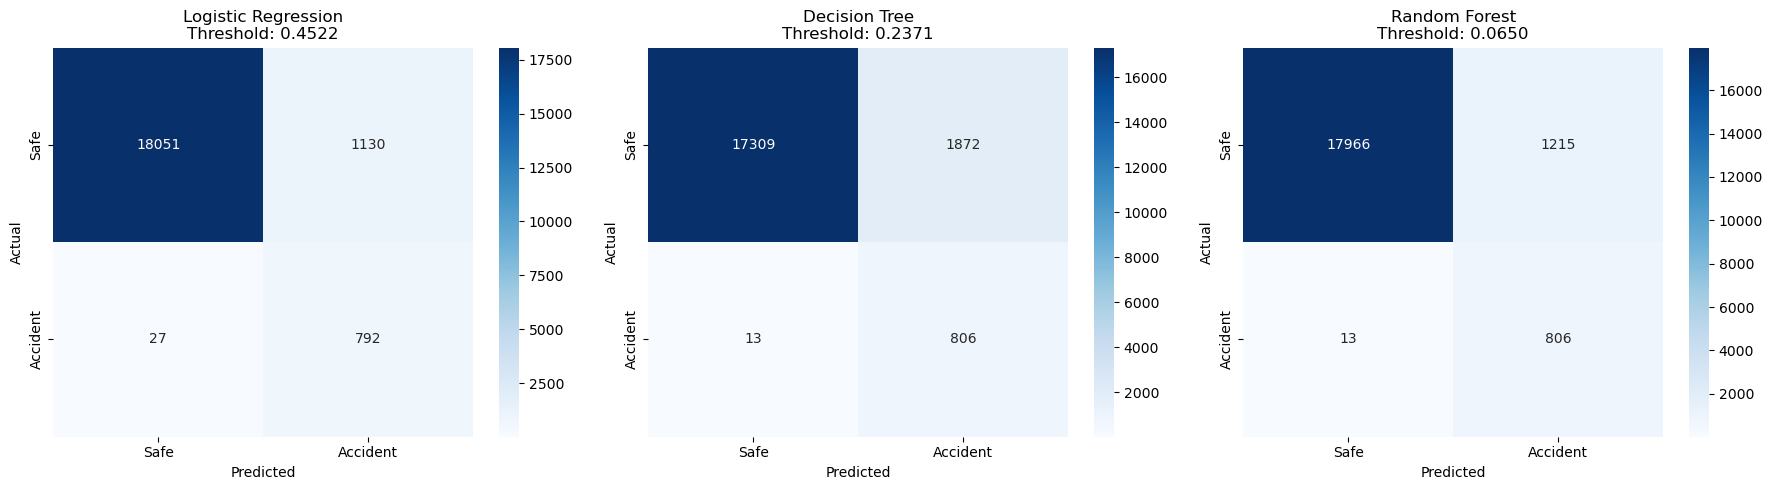

In [ ]:
# Display confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
test_results = []
for i, (name, model) in enumerate(models.items()):

    # Skip models without a valid threshold
    if name not in thresholds:
        axes[i].axis("off")
        continue

    threshold = thresholds[name]

    # Predict on test data
    probs_test = model.predict_proba(X_test)[:, 1]
    pred_test = (probs_test >= threshold).astype(int)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test, pred_test, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    test_results.append({
        "Model": name,
        "Threshold": round(threshold, 4),
        "Test Recall": round(
            recall_score(y_test, pred_test), 4
        ),
        "Test Precision": round(
            precision_score(
                y_test, pred_test, zero_division=0
            ), 4
        ),
        "False Alarm": fp,
        "Missed Accidents": fn
    })

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["Safe", "Accident"],
        yticklabels=["Safe", "Accident"]
    )

    axes[i].set_title(
        f"{name}\nThreshold: {threshold:.4f}"
    )
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [ ]:
# Get feature names after preprocessing
feature_names = rf.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from the Random Forest
importance = pd.Series(
    rf.named_steps["model"].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Top 10 Most Important Encoded Features:")
print(importance.head(10))


Top 10 Most Important Encoded Features:
num__Temp                    0.249669
num__Service_Days            0.248773
num__Pressure                0.181871
onehot__Season_Spring        0.095062
onehot__Season_Autumn        0.031633
num__Age                     0.026842
num__Temp_Gas_Interaction    0.023515
num__Gas                     0.015893
onehot__Season_Summer        0.014952
num__Speed                   0.014417
dtype: float64


In [79]:
import joblib 

In [80]:
joblib.dump(
    {
        "model": rf,
        "threshold": 0.0650
    },
    "fire_risk_model.pkl"
)

['fire_risk_model.pkl']

In [88]:
saved = joblib.load("fire_risk_model.pkl")

rf = saved["model"]
threshold = saved["threshold"]

In [89]:
if hasattr(rf, "feature_names_in_"):
    print("Model features:")
    print(list(rf.feature_names_in_))
else:
    print("Feature names model obyektində saxlanılmayıb.")

Model features:
['Factory', 'Region', 'Shift', 'Workers', 'Exp', 'Training', 'Temp', 'Pressure', 'Humidity', 'Vibration', 'Speed', 'Age', 'Service_Days', 'Gas', 'Sparks', 'Alarm', 'Season', 'Gas_Level', 'Machine_Age_Group', 'Temp_Gas_Interaction']
